# Laboratorium 6: pooling i pełna CNN

Autor: Adam Pastuszak

Kod do sprawozdania, samo sprawozdanie jest w osobnym pliku PDF

## 1. Importy i ustawienia

In [1]:
import copy
import platform
import statistics
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, TensorDataset

SEEDS = [0, 1, 2]
EPOCHS = 10
LR = 1e-3
BATCH = 128
WARIANTY = {"max": "max pooling", "avg": "average pooling",
            "stride": "splot stride 2"}
device = "cuda" if torch.cuda.is_available() else "cpu"
sprzet = (torch.cuda.get_device_name(0) if device == "cuda"
          else f"CPU {platform.processor() or platform.machine()}, "
               f"{torch.get_num_threads()} wątki")
print("PyTorch:", torch.__version__, "| urządzenie:", device, "|", sprzet)

PyTorch: 2.15.0+cu132 | urządzenie: cpu | CPU x86_64, 2 wątki


## 2. Dane: FashionMNIST, podział trening / walidacja / test

60 000 obrazów treningowych dzielę na 50 000 do uczenia i 10 000 do walidacji,
ta sama permutacja z ziarnem 42 co na zajęciach 2, średnią i odchylenie liczę
tylko na 50 000 obrazów treningowych, test jest używany tylko do oceny końcowej

In [2]:
train_raw = torchvision.datasets.FashionMNIST("./data", train=True,
                                              download=True)
test_raw = torchvision.datasets.FashionMNIST("./data", train=False,
                                             download=True)
classes = train_raw.classes

x_full = train_raw.data.float().div(255).unsqueeze(1)
y_full = train_raw.targets
x_test = test_raw.data.float().div(255).unsqueeze(1)
y_test = test_raw.targets

perm = torch.randperm(len(x_full), generator=torch.Generator().manual_seed(42))
train_idx, val_idx = perm[:50000], perm[50000:]
mean = x_full[train_idx].mean().item()
std = x_full[train_idx].std().item()


def norm(x):
    return (x - mean) / std


train_ds = TensorDataset(norm(x_full[train_idx]), y_full[train_idx])
val_dl = DataLoader(TensorDataset(norm(x_full[val_idx]), y_full[val_idx]),
                    batch_size=1000)
test_dl = DataLoader(TensorDataset(norm(x_test), y_test), batch_size=1000)
print(f"trening: {len(train_ds)} | walidacja: {len(val_idx)} | "
      f"test: {len(y_test)} | obraz: {tuple(x_full.shape[1:])}")
print(f"normalizacja z części treningowej: mean {mean:.4f}, std {std:.4f}")

trening: 50000 | walidacja: 10000 | test: 10000 | obraz: (1, 28, 28)
normalizacja z części treningowej: mean 0.2857, std 0.3529


## 3. Pełna CNN z trzema wariantami redukcji

Blok: splot 3x3 → BatchNorm → ReLU → redukcja, dwa bloki (32 i 64 filtry),
na końcu GAP → Flatten → Linear, redukcja to max pooling 2x2, average pooling
2x2 albo dodatkowy splot 3x3 ze stride 2 (z BatchNorm i ReLU)

In [3]:
class CNN(nn.Module):
    def __init__(self, pool="max", n_classes=10):
        super().__init__()

        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1),
                      nn.BatchNorm2d(cout), nn.ReLU()]
            if pool == "max":
                layers.append(nn.MaxPool2d(2))
            elif pool == "avg":
                layers.append(nn.AvgPool2d(2))
            elif pool == "stride":
                layers += [nn.Conv2d(cout, cout, 3, stride=2, padding=1),
                           nn.BatchNorm2d(cout), nn.ReLU()]
            return nn.Sequential(*layers)

        self.features = nn.Sequential(block(1, 32), block(32, 64))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Linear(64, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


def count_params(m):
    return sum(p.numel() for p in m.parameters())


info = {}
x0 = torch.zeros(2, 1, 28, 28)
for p in WARIANTY:
    m = CNN(p).eval()
    with torch.no_grad():
        b1 = m.features[0](x0)
        b2 = m.features[1](b1)
        out = m.head(b2)
    info[p] = {"params": count_params(m),
               "mapa": " x ".join(str(d) for d in b2.shape[1:])}
    print(f"{WARIANTY[p]:16s} | po bloku 1 {tuple(b1.shape[1:])} | "
          f"przed głowicą {tuple(b2.shape[1:])} = {b2[0].numel()} liczb | "
          f"wyjście {tuple(out.shape)}")
    print(f"{'':16s} | parametry: blok 1 {count_params(m.features[0]):,} | "
          f"blok 2 {count_params(m.features[1]):,} | "
          f"głowica {count_params(m.head):,} | razem {info[p]['params']:,}")
extra = info["stride"]["params"] - info["max"]["params"]
print(f"splot stride 2 dodaje {extra:,} parametrów względem poolingu")

max pooling      | po bloku 1 (32, 14, 14) | przed głowicą (64, 7, 7) = 3136 liczb | wyjście (2, 10)
                 | parametry: blok 1 384 | blok 2 18,624 | głowica 650 | razem 19,658
average pooling  | po bloku 1 (32, 14, 14) | przed głowicą (64, 7, 7) = 3136 liczb | wyjście (2, 10)
                 | parametry: blok 1 384 | blok 2 18,624 | głowica 650 | razem 19,658
splot stride 2   | po bloku 1 (32, 14, 14) | przed głowicą (64, 7, 7) = 3136 liczb | wyjście (2, 10)
                 | parametry: blok 1 9,696 | blok 2 55,680 | głowica 650 | razem 66,026
splot stride 2 dodaje 46,368 parametrów względem poolingu


## 4. Uczenie i ocena

Te same ustawienia dla każdego wariantu: Adam, lr 0.001, batch 128, 10 epok,
CrossEntropyLoss, bez augmentacji, po uczeniu przywracam wagi z epoki
z najwyższą accuracy walidacyjną, czas liczę tylko dla pętli uczenia

In [4]:
@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss_sum += nn.functional.cross_entropy(out, yb,
                                                reduction="sum").item()
        correct += (out.argmax(1) == yb).sum().item()
        n += len(yb)
    return loss_sum / n, correct / n * 100


def train_model(model, seed):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    crit = nn.CrossEntropyLoss()
    train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                          generator=torch.Generator().manual_seed(seed))
    hist = {"train_acc": [], "val_acc": [], "val_loss": []}
    best = (-1.0, 0, None)
    czas = 0.0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        correct, n = 0, 0
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            out = model(xb)
            crit(out, yb).backward()
            opt.step()
            correct += (out.argmax(1) == yb).sum().item()
            n += len(yb)
        if device == "cuda":
            torch.cuda.synchronize()
        czas += time.time() - t0
        val_loss, val_acc = evaluate(model, val_dl)
        hist["train_acc"].append(correct / n * 100)
        hist["val_acc"].append(val_acc)
        hist["val_loss"].append(val_loss)
        if val_acc > best[0]:
            best = (val_acc, epoch, copy.deepcopy(model.state_dict()))
    model.load_state_dict(best[2])
    return model, hist, best[1], best[0], czas

## 5. Eksperyment: 3 warianty x 3 ziarna

Każdy wariant uczę 3 razy (ziarno 0, 1, 2 dla wag i kolejności paczek),
test liczę raz na koniec każdego przebiegu, dla wag z wybranej epoki

In [5]:
runs = {p: [] for p in WARIANTY}
for seed in SEEDS:
    for p in WARIANTY:
        torch.manual_seed(seed)
        model, hist, ep, val_acc, czas = train_model(CNN(p), seed)
        test_acc = evaluate(model, test_dl)[1]
        runs[p].append({"hist": hist, "epoka": ep, "val": val_acc,
                        "test": test_acc, "czas": czas})
        print(f"ziarno {seed} | {WARIANTY[p]:16s} | epoka {ep:2d} | "
              f"acc walid. {val_acc:.2f}% | acc test {test_acc:.2f}% | "
              f"czas {czas:.1f} s")

ziarno 0 | max pooling      | epoka  8 | acc walid. 84.68% | acc test 84.01% | czas 178.6 s


ziarno 0 | average pooling  | epoka  8 | acc walid. 80.65% | acc test 80.06% | czas 178.6 s


ziarno 0 | splot stride 2   | epoka  9 | acc walid. 90.39% | acc test 89.80% | czas 199.4 s


ziarno 1 | max pooling      | epoka 10 | acc walid. 85.78% | acc test 84.87% | czas 154.2 s


ziarno 1 | average pooling  | epoka 10 | acc walid. 83.01% | acc test 82.97% | czas 164.4 s


ziarno 1 | splot stride 2   | epoka  9 | acc walid. 90.39% | acc test 89.21% | czas 214.9 s


ziarno 2 | max pooling      | epoka  9 | acc walid. 85.34% | acc test 84.67% | czas 173.3 s


ziarno 2 | average pooling  | epoka 10 | acc walid. 82.71% | acc test 82.07% | czas 179.9 s


ziarno 2 | splot stride 2   | epoka  8 | acc walid. 90.84% | acc test 90.11% | czas 223.1 s


## 6. Wyniki

In [6]:
def sr(xs):
    return statistics.mean(xs)


def od(xs):
    return statistics.stdev(xs)


print(f"{'wariant':16s} | {'parametry':>9s} | {'mapa przed głowicą':>18s} | "
      f"{'epoki':>8s} | {'acc walid.':>10s} | {'acc test':>15s} | "
      f"{'czas/epokę':>10s}")
print("-" * 104)
for p, nazwa in WARIANTY.items():
    r = runs[p]
    val = [x["val"] for x in r]
    test = [x["test"] for x in r]
    epoki = ", ".join(str(x["epoka"]) for x in r)
    czas = sr([x["czas"] for x in r]) / EPOCHS
    print(f"{nazwa:16s} | {info[p]['params']:>9,} | "
          f"{info[p]['mapa']:>18s} | {epoki:>8s} | {sr(val):>9.2f}% | "
          f"{sr(test):>6.2f}% ± {od(test):.2f} | {czas:>8.1f} s")
print(f"\nśrednia i odchylenie z {len(SEEDS)} przebiegów | lr {LR}, "
      f"batch {BATCH}, {EPOCHS} epok, Adam | {sprzet}")

print(f"\n{'acc test':16s} | " + " | ".join(f"ziarno {s}" for s in SEEDS))
for p, nazwa in WARIANTY.items():
    print(f"{nazwa:16s} | " + " | ".join(
        f"{x['test']:7.2f}%" for x in runs[p]))

wariant          | parametry | mapa przed głowicą |    epoki | acc walid. |        acc test | czas/epokę
--------------------------------------------------------------------------------------------------------
max pooling      |    19,658 |         64 x 7 x 7 | 8, 10, 9 |     85.27% |  84.52% ± 0.45 |     16.9 s
average pooling  |    19,658 |         64 x 7 x 7 | 8, 10, 10 |     82.12% |  81.70% ± 1.49 |     17.4 s
splot stride 2   |    66,026 |         64 x 7 x 7 |  9, 9, 8 |     90.54% |  89.71% ± 0.46 |     21.2 s

średnia i odchylenie z 3 przebiegów | lr 0.001, batch 128, 10 epok, Adam | CPU x86_64, 2 wątki

acc test         | ziarno 0 | ziarno 1 | ziarno 2
max pooling      |   84.01% |   84.87% |   84.67%
average pooling  |   80.06% |   82.97% |   82.07%
splot stride 2   |   89.80% |   89.21% |   90.11%


## 7. Krzywe accuracy

Średnia z 3 przebiegów, po lewej trening (przerywana) i walidacja (ciągła),
po prawej sama walidacja w powiększeniu, pasek to zakres min-max z 3 przebiegów

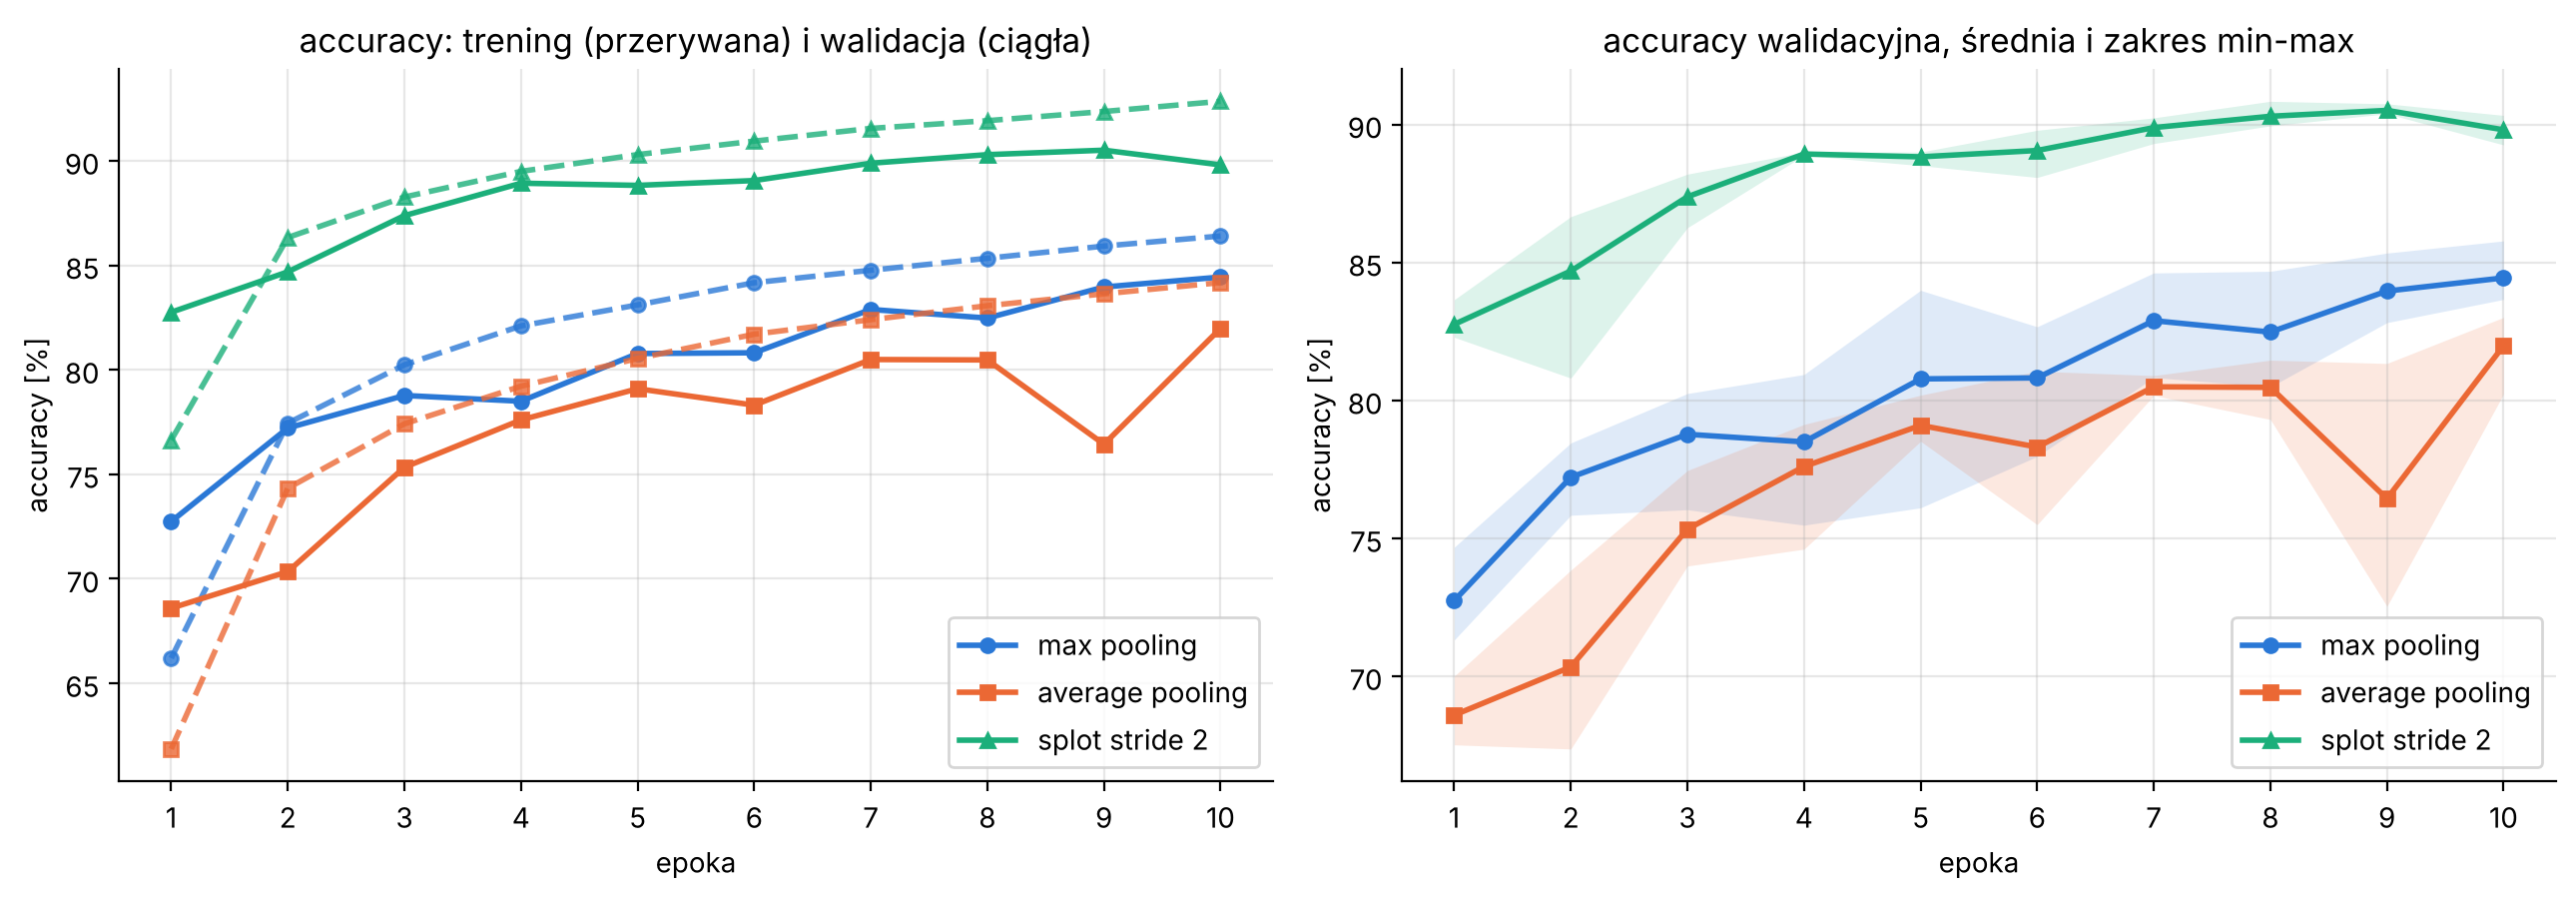

In [7]:
KOLORY = {"max": "#2a78d6", "avg": "#eb6834", "stride": "#1baf7a"}
ZNACZNIKI = {"max": "o", "avg": "s", "stride": "^"}
ep = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for p, nazwa in WARIANTY.items():
    tr = torch.tensor([x["hist"]["train_acc"] for x in runs[p]])
    va = torch.tensor([x["hist"]["val_acc"] for x in runs[p]])
    kw = dict(color=KOLORY[p], marker=ZNACZNIKI[p], markersize=5,
              linewidth=2)
    axes[0].plot(ep, tr.mean(0), "--", alpha=0.8, **kw)
    axes[0].plot(ep, va.mean(0), "-", label=nazwa, **kw)
    axes[1].fill_between(ep, va.min(0).values, va.max(0).values,
                         color=KOLORY[p], alpha=0.15, linewidth=0)
    axes[1].plot(ep, va.mean(0), "-", label=nazwa, **kw)
axes[0].set_title("accuracy: trening (przerywana) i walidacja (ciągła)")
axes[1].set_title("accuracy walidacyjna, średnia i zakres min-max")
for ax in axes:
    ax.set_xlabel("epoka")
    ax.set_ylabel("accuracy [%]")
    ax.set_xticks(list(ep))
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()